Model found at C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\2_unet_trained.pth


Use existing model? (y/n):  y


Using existing model...
Model loaded from C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\2_unet_trained.pth
Found 68 images

[1/3] Processing: pic1_0_0.png


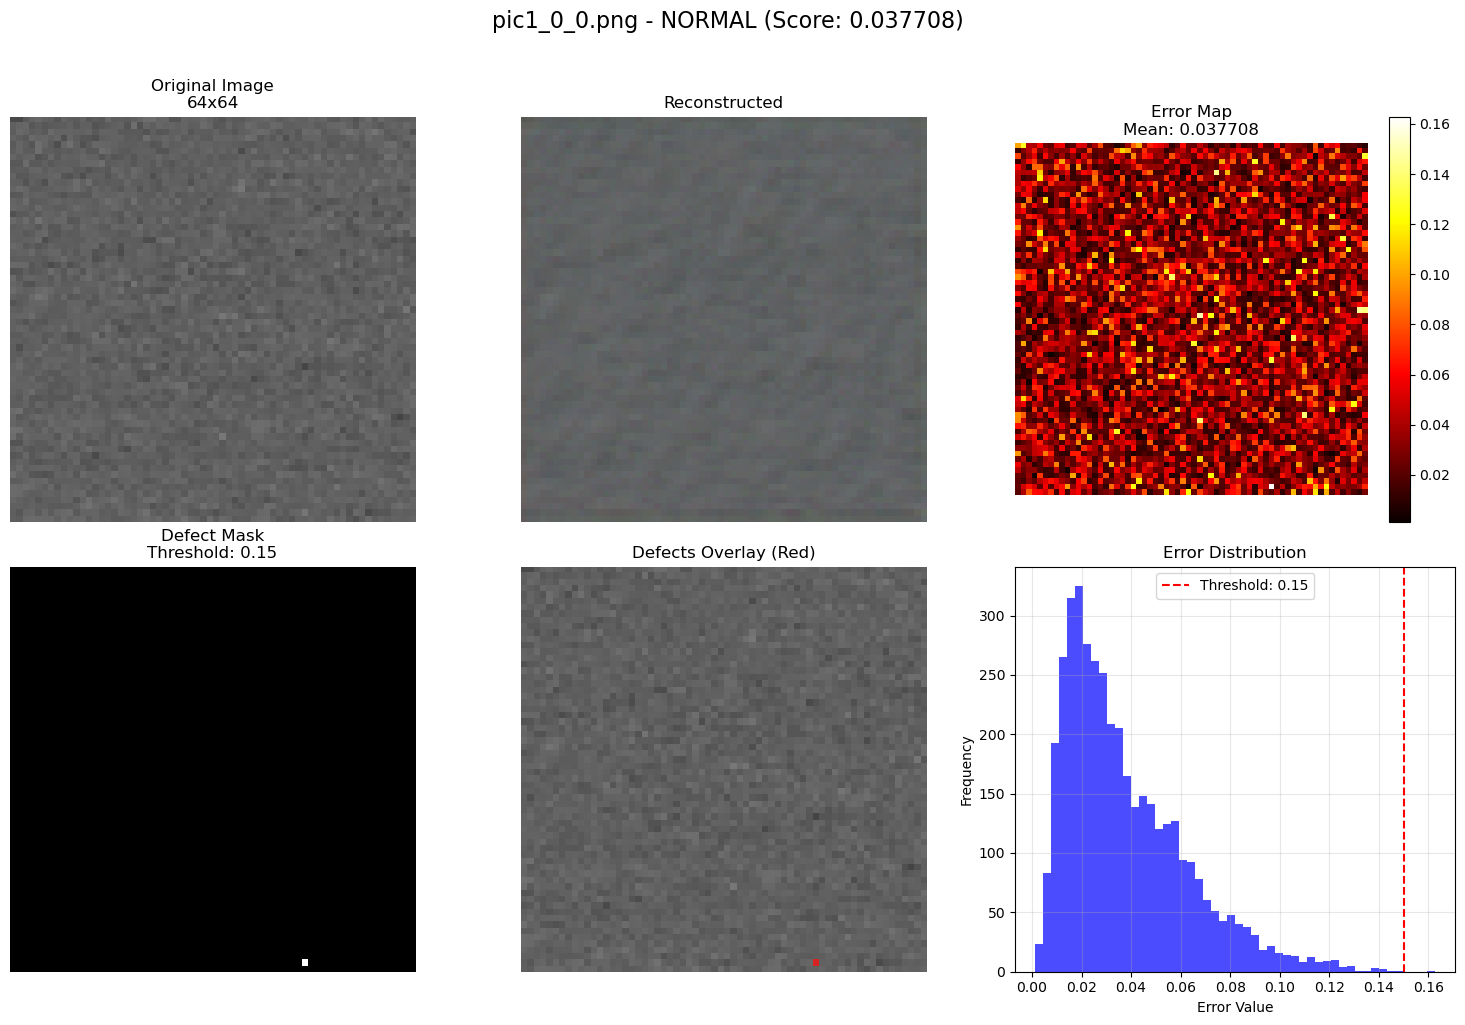


Results for pic1_0_0.png:
  Defect Score: 0.037708
  Threshold: 0.15
  Classification: NORMAL
  Max Error: 0.162870
  Defect Area: 0.02%

[2/3] Processing: pic1_0_1.png


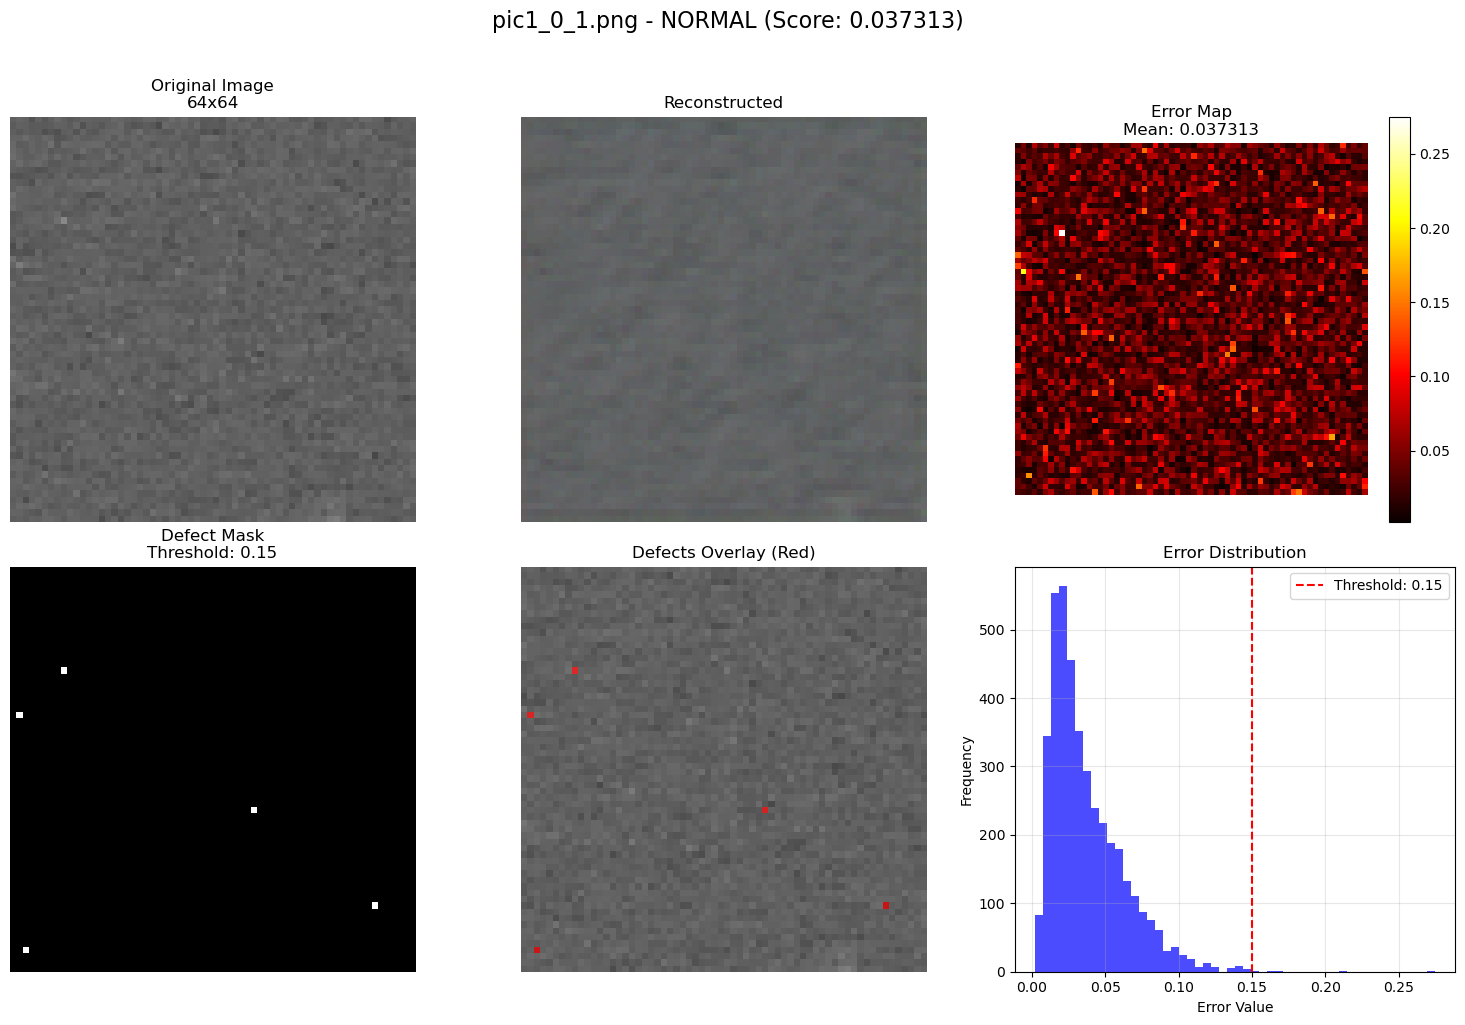


Results for pic1_0_1.png:
  Defect Score: 0.037313
  Threshold: 0.15
  Classification: NORMAL
  Max Error: 0.274986
  Defect Area: 0.12%

[3/3] Processing: pic1_0_14.png


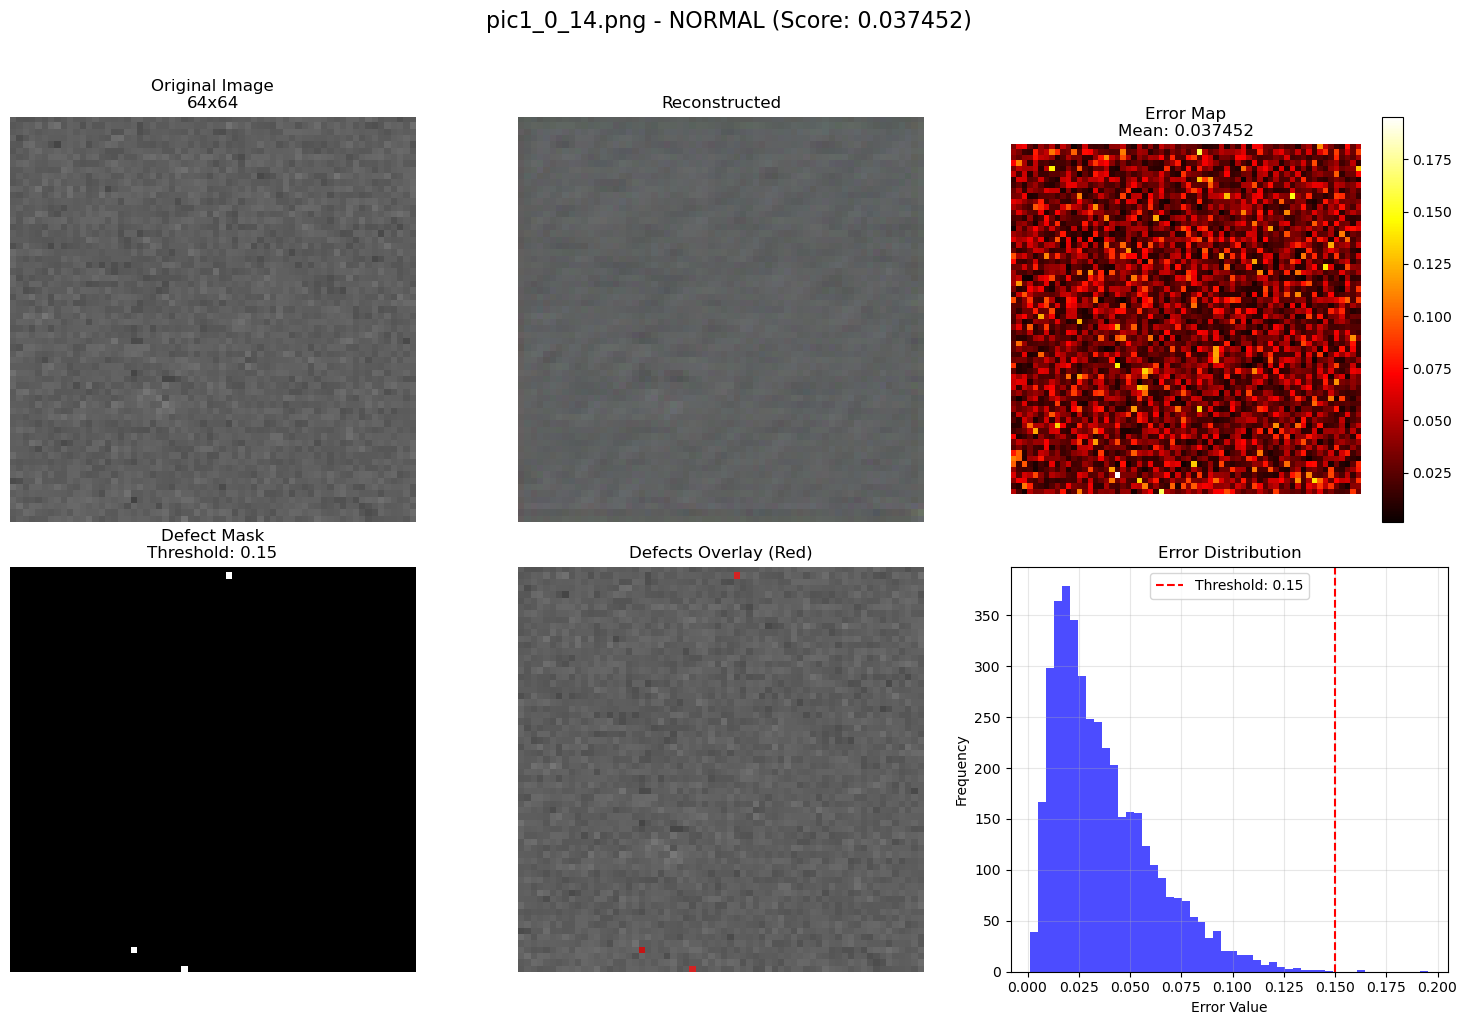

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.029944897..1.0674474].



Results for pic1_0_14.png:
  Defect Score: 0.037452
  Threshold: 0.15
  Classification: NORMAL
  Max Error: 0.195432
  Defect Area: 0.07%
Found 66 images

[1/3] Processing: pic2_8_16.jpg


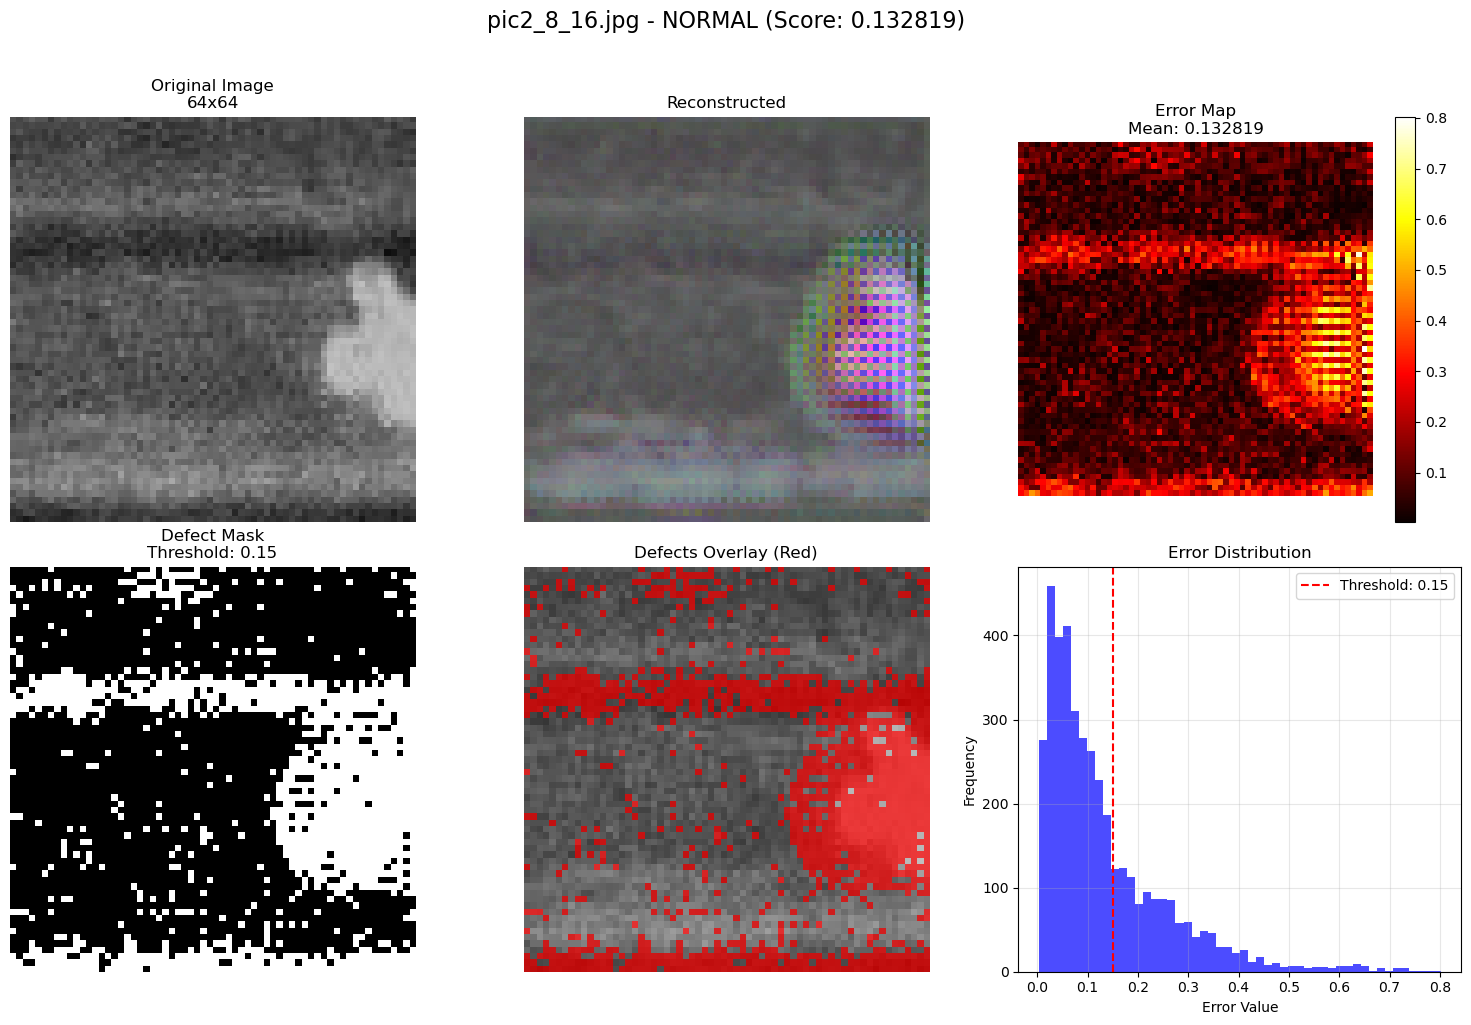

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9296886..1.4639363].



Results for pic2_8_16.jpg:
  Defect Score: 0.132819
  Threshold: 0.15
  Classification: NORMAL
  Max Error: 0.802386
  Defect Area: 30.66%

[2/3] Processing: pic2_8_17.jpg


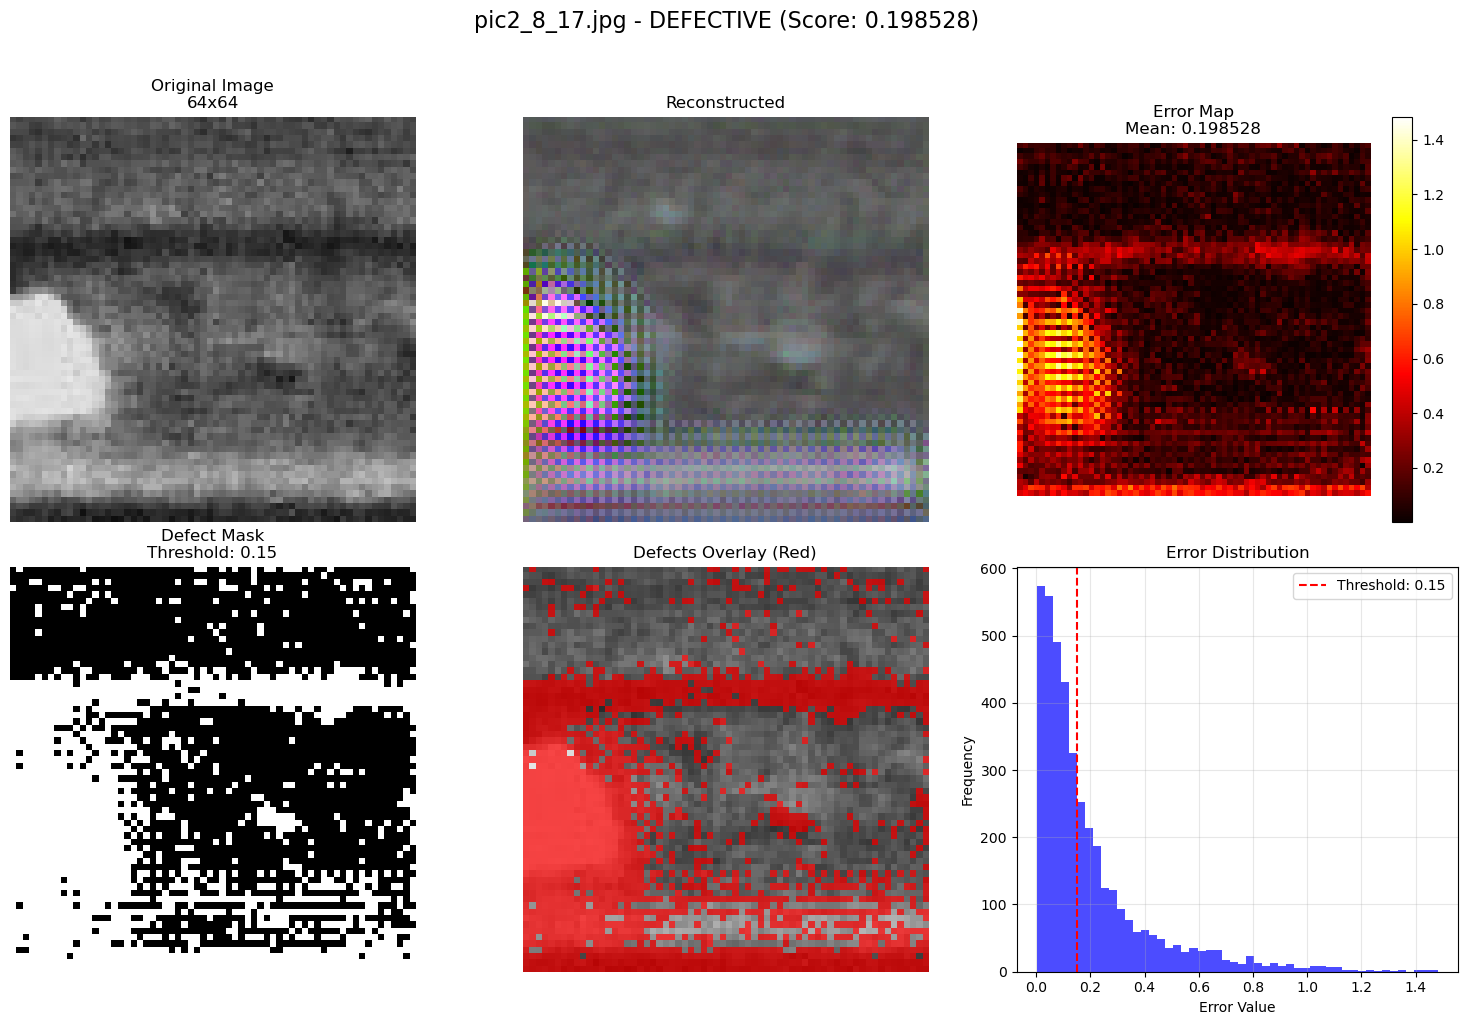


Results for pic2_8_17.jpg:
  Defect Score: 0.198528
  Threshold: 0.15
  Classification: DEFECTIVE
  Max Error: 1.483953
  Defect Area: 42.16%

[3/3] Processing: pic3_10_15.png


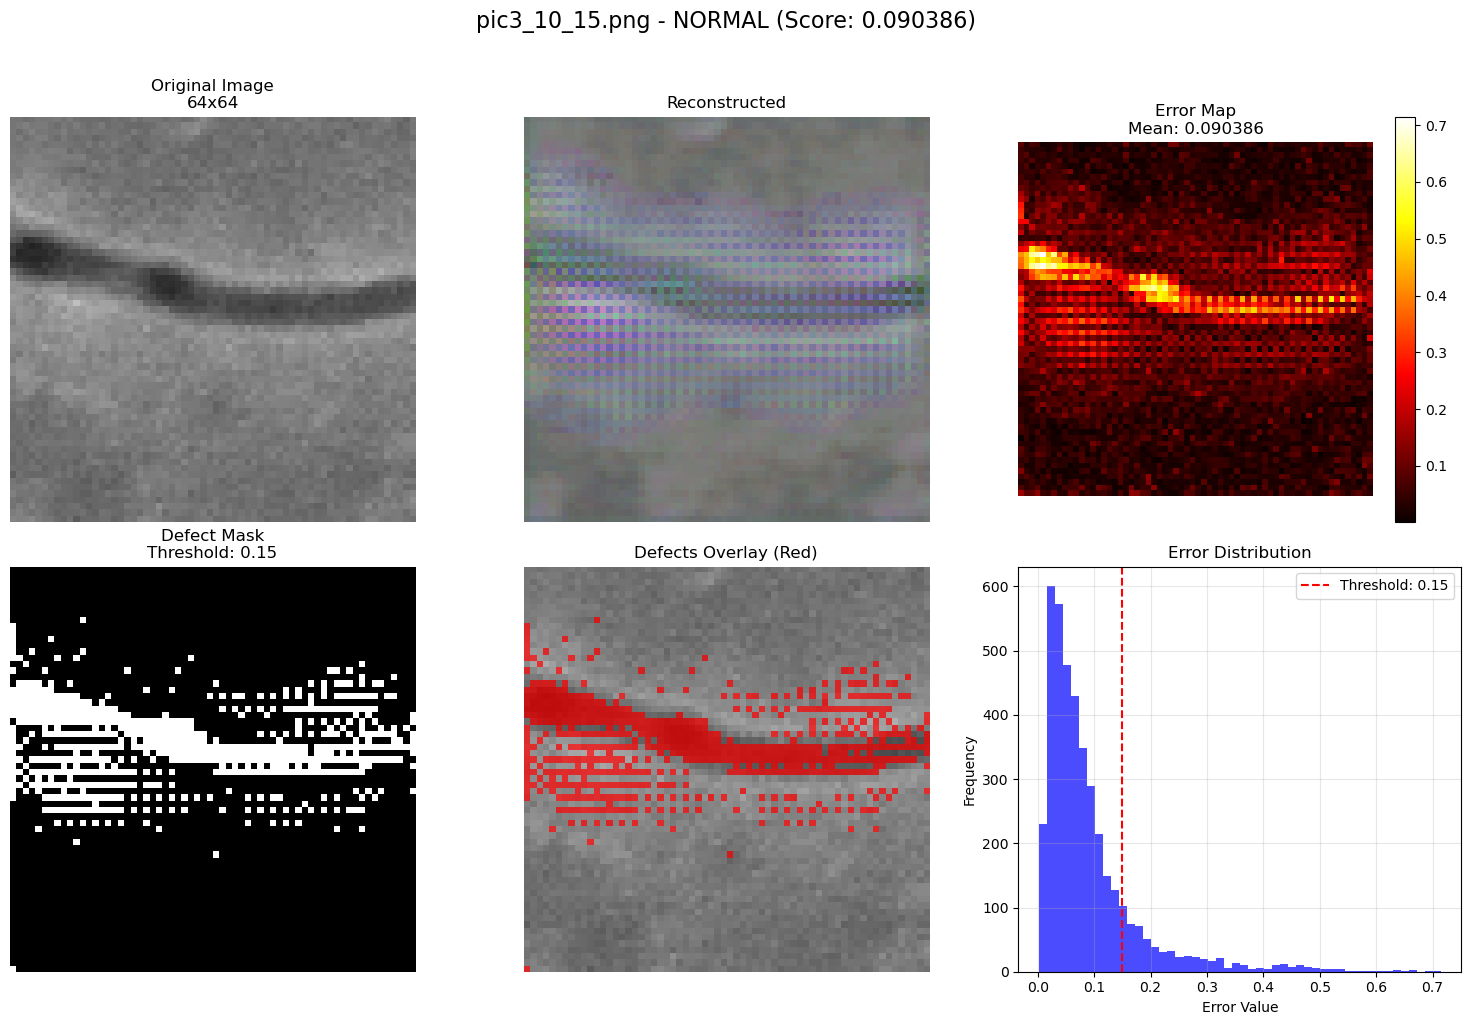


Results for pic3_10_15.png:
  Defect Score: 0.090386
  Threshold: 0.15
  Classification: NORMAL
  Max Error: 0.714966
  Defect Area: 14.97%


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from PIL import Image
import matplotlib.pyplot as plt

NORMAL_DIR = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_normalimags"
DEFECT_DIR = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_abnormalimags"
MODEL_PATH = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\2_unet_trained.pth"
IMG_SIZE = 64  

class SimpleDataset(Dataset):
    def __init__(self, image_dir, img_size=IMG_SIZE):
        self.image_dir = image_dir
        self.img_size = img_size
        self.image_files = []
        
        for f in os.listdir(image_dir):
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                self.image_files.append(f)
        
        print(f"Found {len(self.image_files)} images")
        
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
        ])
    
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, image


class SimpleUNet(nn.Module):
    def __init__(self):
        super(SimpleUNet, self).__init__()

        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)
        
        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        
        self.out = nn.Conv2d(16, 3, 1)
        
    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        
        b = self.bottleneck(p2)
        
        u2 = self.up2(b)
        if u2.shape != e2.shape:
            u2 = torch.nn.functional.interpolate(u2, size=e2.shape[2:], mode='bilinear')
        d2 = self.dec2(torch.cat([u2, e2], dim=1))
        
        u1 = self.up1(d2)
        if u1.shape != e1.shape:
            u1 = torch.nn.functional.interpolate(u1, size=e1.shape[2:], mode='bilinear')
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        
        return self.out(d1)

def train_unet():
    if not os.path.exists(NORMAL_DIR):
        return None

    dataset = SimpleDataset(NORMAL_DIR, img_size=IMG_SIZE)
    
    if len(dataset) == 0:
        return None

    dataloader = DataLoader(
        dataset,
        batch_size=4,
        shuffle=True,
        num_workers=0
    )

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    model = SimpleUNet().to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    for epoch in range(20):
        model.train()
        epoch_loss = 0
        batch_count = 0
        
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            batch_count += 1

        avg_loss = epoch_loss / batch_count
        print(f"Epoch {epoch+1}/20: Loss = {avg_loss:.6f}")
        
        if (epoch + 1) % 5 == 0:
            checkpoint = f"checkpoint_epoch_{epoch+1}.pth"
            torch.save(model.state_dict(), checkpoint)
            print(f"  Saved: {checkpoint}")

    torch.save(model.state_dict(), MODEL_PATH)
    print(f"\nModel saved to {MODEL_PATH}")
    
    model.eval()
    with torch.no_grad():
        test_img, _ = dataset[0]
        test_img = test_img.unsqueeze(0).to(device)
        reconstructed = model(test_img)
        test_loss = criterion(reconstructed, test_img)
    return model

class DefectDetector:
    def __init__(self, model_path):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = SimpleUNet().to(self.device)
        
        self.model.load_state_dict(torch.load(model_path, map_location=self.device, weights_only=False))
        self.model.eval()
        print(f"Model loaded from {model_path}")
        
        self.transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
        ])
        
    def denormalize(self, tensor):
        return tensor * 0.5 + 0.5
    
    def detect_and_visualize(self, image_path, threshold=0.1):
        original_image = Image.open(image_path).convert('RGB')
        original_size = original_image.size  
        
        input_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        
        with torch.no_grad():
            reconstructed = self.model(input_tensor)
            
            error = torch.abs(input_tensor - reconstructed)
            error_map_small = error.mean(dim=1, keepdim=True) 
        
        # Resize error map to original image size for visualization
        error_resized = torch.nn.functional.interpolate(
            error_map_small,
            size=original_size[::-1],  # (height, width)
            mode='bilinear',
            align_corners=False
        )
        
        error_np_large = error_resized.squeeze().cpu().numpy()  # At original size
        error_np_small = error_map_small.squeeze().cpu().numpy()  # At model size
        
        defect_mask_large = (error_np_large > threshold).astype(np.uint8) * 255
        
        defect_score = error_np_small.mean()
        is_defective = defect_score > threshold

        original_display = self.denormalize(input_tensor).squeeze().cpu()
        recon_display = self.denormalize(reconstructed).squeeze().cpu()
        
        original_display_large = torch.nn.functional.interpolate(
            original_display.unsqueeze(0),
            size=original_size[::-1],
            mode='bilinear'
        ).squeeze().permute(1, 2, 0).numpy()
        
        recon_display_large = torch.nn.functional.interpolate(
            recon_display.unsqueeze(0),
            size=original_size[::-1],
            mode='bilinear'
        ).squeeze().permute(1, 2, 0).numpy()

        fig, axes = plt.subplots(2, 3, figsize=(15, 10))

        axes[0, 0].imshow(original_display_large)
        axes[0, 0].set_title(f'Original Image\n{original_size[0]}x{original_size[1]}')
        axes[0, 0].axis('off')

        axes[0, 1].imshow(recon_display_large)
        axes[0, 1].set_title('Reconstructed')
        axes[0, 1].axis('off')

        im1 = axes[0, 2].imshow(error_np_large, cmap='hot')
        axes[0, 2].set_title(f'Error Map\nMean: {defect_score:.6f}')
        axes[0, 2].axis('off')
        plt.colorbar(im1, ax=axes[0, 2])
        
        axes[1, 0].imshow(defect_mask_large, cmap='gray')
        axes[1, 0].set_title(f'Defect Mask\nThreshold: {threshold}')
        axes[1, 0].axis('off')

        overlay = original_display_large.copy()
        mask_bool = defect_mask_large > 127 

        red_overlay = np.zeros_like(overlay)
        red_overlay[..., 0] = 1.0  

        alpha = 0.7
        overlay[mask_bool] = overlay[mask_bool] * (1 - alpha) + red_overlay[mask_bool] * alpha
        
        axes[1, 1].imshow(overlay)
        axes[1, 1].set_title('Defects Overlay (Red)')
        axes[1, 1].axis('off')

        axes[1, 2].hist(error_np_large.flatten(), bins=50, color='blue', alpha=0.7)
        axes[1, 2].axvline(x=threshold, color='red', linestyle='--', label=f'Threshold: {threshold}')
        axes[1, 2].set_title('Error Distribution')
        axes[1, 2].set_xlabel('Error Value')
        axes[1, 2].set_ylabel('Frequency')
        axes[1, 2].legend()
        axes[1, 2].grid(True, alpha=0.3)

        status = "DEFECTIVE" if is_defective else "NORMAL"
        plt.suptitle(f'{os.path.basename(image_path)} - {status} (Score: {defect_score:.6f})', 
                    fontsize=16, y=1.02)
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nResults for {os.path.basename(image_path)}:")
        print(f"  Defect Score: {defect_score:.6f}")
        print(f"  Threshold: {threshold}")
        print(f"  Classification: {status}")
        print(f"  Max Error: {error_np_large.max():.6f}")
        defect_area_percentage = (mask_bool.sum() / mask_bool.size) * 100
        print(f"  Defect Area: {defect_area_percentage:.2f}%")
        
        return {
            'defect_score': defect_score,
            'is_defective': is_defective,
            'error_map': error_np_large,
            'defect_mask': defect_mask_large,
            'original': original_display_large,
            'reconstructed': recon_display_large
        }
    
    def batch_test(self, image_dir, threshold=0.1):
        if not os.path.exists(image_dir):
            print(f"Directory not found: {image_dir}")
            return

        image_files = []
        for f in os.listdir(image_dir):
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                image_files.append(os.path.join(image_dir, f))
        
        print(f"Found {len(image_files)} images")
        
        if len(image_files) == 0:
            return
        
        for i, img_path in enumerate(image_files[:3]):
            print(f"\n[{i+1}/{min(3, len(image_files))}] Processing: {os.path.basename(img_path)}")
            self.detect_and_visualize(img_path, threshold)

if __name__ == "__main__":
    if not os.path.exists(MODEL_PATH):
        model = train_unet()
    else:
        print(f"Model found at {MODEL_PATH}")
        use_existing = input("Use existing model? (y/n): ").strip().lower()
        if use_existing == 'y':
            print("Using existing model...")
        else:
            print("Training new model...")
            model = train_unet()
    detector = DefectDetector(MODEL_PATH)
    

    detector.batch_test(NORMAL_DIR, threshold=0.15)
    
    if os.path.exists(DEFECT_DIR):
        detector.batch_test(DEFECT_DIR, threshold=0.15)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import os
import glob
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
import random

In [2]:
class SimpleUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(SimpleUNet, self).__init__()
        
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)
        
        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )

        self.out = nn.Conv2d(16, 3, 1)
        
    def forward(self, x):
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        b = self.bottleneck(p2)
        
        u2 = self.up2(b)
        if u2.shape != e2.shape:
            u2 = torch.nn.functional.interpolate(u2, size=e2.shape[2:], mode='bilinear')
        d2 = self.dec2(torch.cat([u2, e2], dim=1))
        
        u1 = self.up1(d2)
        if u1.shape != e1.shape:
            u1 = torch.nn.functional.interpolate(u1, size=e1.shape[2:], mode='bilinear')
        d1 = self.dec1(torch.cat([u1, e1], dim=1))
        
        return self.out(d1)




In [9]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5, img_channels=3):
        super(Generator, self).__init__()
        self.num_classes = num_classes
        self.latent_dim = latent_dim
        
        self.init_size = 16
        self.label_embedding = nn.Embedding(num_classes, latent_dim)
        
        self.l1 = nn.Sequential(nn.Linear(latent_dim * 2, 128 * self.init_size ** 2))
        
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 128, 3, stride=1, padding=1),
            nn.BatchNorm2d(128, 0.8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.1),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, stride=1, padding=1),
            nn.BatchNorm2d(64, 0.8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, img_channels, 3, stride=1, padding=1),
            nn.Tanh()
        )
    
    def forward(self, z, labels):
        label_embed = self.label_embedding(labels)
        gen_input = torch.cat((label_embed, z), -1)
        
        out = self.l1(gen_input)
        out = out.view(out.shape[0], 128, self.init_size, self.init_size)
        img = self.conv_blocks(out)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes=5, img_channels=3):
        super(Discriminator, self).__init__()
        
        def discriminator_block(in_filters, out_filters, bn=True):
            block = [nn.Conv2d(in_filters, out_filters, 3, 2, 1),
                    nn.LeakyReLU(0.2, inplace=True),
                    nn.Dropout2d(0.3)]
            if bn:
                block.append(nn.BatchNorm2d(out_filters, 0.8))
            return block
        
        self.model = nn.Sequential(
            *discriminator_block(img_channels, 16, bn=False),
            *discriminator_block(16, 32),
            *discriminator_block(32, 64),
            *discriminator_block(64, 128),
        )
        
        ds_size = 64 // 2 ** 4
        self.adv_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, 1), nn.Sigmoid())
        self.aux_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, num_classes), nn.Softmax(dim=1))


    def forward(self, img):
        out = self.model(img)
        out = out.view(out.shape[0], -1)
        validity = self.adv_layer(out)
        label = self.aux_layer(out)
        return validity, label 




In [10]:
class ACGANDataset(Dataset):
    def __init__(self, normal_folder, defect_folders, transform=None, img_size=64):
        self.transform = transform
        self.img_size = img_size
        self.image_paths = []
        self.labels = []
        
        self.class_names = ['normal', 'abrasive', 'adhasive', 'cracks', 'delamination']
        
        normal_images = self._get_image_paths(normal_folder)
        self.image_paths.extend(normal_images)
        self.labels.extend([0] * len(normal_images))
        
        for i, defect_folder in enumerate(defect_folders, 1):
            defect_images = self._get_image_paths(defect_folder)
            self.image_paths.extend(defect_images)
            self.labels.extend([i] * len(defect_images))
        
        print(f"Loaded {len(self.image_paths)} images")
        for i, class_name in enumerate(self.class_names):
            count = sum(1 for label in self.labels if label == i)
            print(f"Class {class_name}: {count} images")
    
    def _get_image_paths(self, folder_path):
        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG', '*.BMP']
        image_paths = []
        
        for extension in extensions:
            image_paths.extend(glob.glob(os.path.join(folder_path, extension)))
        
        return image_paths
        
    def __len__(self):
        return len(self.image_paths)
        
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        try:
            image = Image.open(img_path).convert('RGB')
            
            if self.transform:
                image = self.transform(image)
            else:
                transform = transforms.Compose([
                    transforms.Resize((self.img_size, self.img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize([0.5] * 3, [0.5] * 3)
                ])
                image = transform(image)
                
            return image, label
            
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            dummy_image = torch.zeros(3, self.img_size, self.img_size)
            return dummy_image, label


In [11]:
class ACGANAnomalyDetection:
    def __init__(self, num_classes=5, img_size=64, channels=3, latent_dim=100):
        self.num_classes = num_classes
        self.img_size = img_size
        self.channels = channels
        self.latent_dim = latent_dim
        
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        self.unet = SimpleUNet(in_channels=3, out_channels=1).to(self.device)
        self.generator = Generator(latent_dim, num_classes, channels).to(self.device)
        self.discriminator = Discriminator(num_classes, channels).to(self.device)
        
        if os.path.exists(r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\2_unet_trained.pth"):
            self.unet.load_state_dict(torch.load(r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\2_unet_trained.pth", map_location=self.device))
        
        self.adversarial_loss = nn.BCELoss()
        self.auxiliary_loss = nn.CrossEntropyLoss()
        self.unet_loss = nn.BCEWithLogitsLoss()
        
        self.optimizer_G = optim.Adam(self.generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
        self.optimizer_D = optim.Adam(self.discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
        self.optimizer_U = optim.Adam(self.unet.parameters(), lr=0.0001, betas=(0.5, 0.999))  # Меньше LR для UNet

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * channels, [0.5] * channels)
        ])
        
        self.class_names = ['normal', 'abrasive', 'adhasive', 'cracks', 'delamination']

        self.fixed_z = torch.randn(num_classes, latent_dim).to(self.device)
        self.fixed_labels = torch.arange(num_classes).to(self.device)

        self.history = {'g_loss': [], 'd_loss': [], 'u_loss': [],
                    'g_adv': [], 'g_aux': [], 'd_adv': [], 'd_aux': []}
    
    def train(self, dataloader, epochs):
        self.generator.train()
        self.discriminator.train()
        self.unet.train()
        
        for epoch in range(epochs):
            epoch_g_loss = 0
            epoch_d_loss = 0
            epoch_u_loss = 0
            
            for i, (imgs, labels) in enumerate(dataloader):
                batch_size = imgs.size(0)
                real_imgs = imgs.to(self.device)
                real_labels = labels.to(self.device)
                
                valid = torch.ones(batch_size, 1, device=self.device)
                fake = torch.zeros(batch_size, 1, device=self.device)

                self.optimizer_G.zero_grad()
                self.optimizer_U.zero_grad()

                gen_labels = torch.randint(0, self.num_classes, (batch_size,), device=self.device)
                z = torch.randn(batch_size, self.latent_dim, device=self.device)
                gen_imgs = self.generator(z, gen_labels)
                
                unet_mask = self.unet(real_imgs)

                validity, pred_label = self.discriminator(gen_imgs)
                g_loss_adv = self.adversarial_loss(validity, valid)
                g_loss_aux = self.auxiliary_loss(pred_label, gen_labels) * 2.0
                
                with torch.no_grad():
                    gan_diff = torch.abs(real_imgs - gen_imgs).mean(dim=1, keepdim=True)
                    pseudo_gt = (gan_diff > 0.3).float()
                    
                    pseudo_gt = pseudo_gt.repeat(1, 3, 1, 1)
                    
                u_loss = self.unet_loss(unet_mask, pseudo_gt) * 0.2
                
                total_g_u_loss = g_loss_adv + g_loss_aux + u_loss
                total_g_u_loss.backward()
                self.optimizer_G.step()
                self.optimizer_U.step()
                
                self.optimizer_D.zero_grad()
                
                real_validity, real_pred_label = self.discriminator(real_imgs)
                d_real_loss_adv = self.adversarial_loss(real_validity, valid)
                d_real_loss_aux = self.auxiliary_loss(real_pred_label, real_labels)
                
                fake_validity, _ = self.discriminator(gen_imgs.detach())
                d_fake_loss_adv = self.adversarial_loss(fake_validity, fake)
                
                d_loss_adv = (d_real_loss_adv + d_fake_loss_adv) / 2
                d_loss_aux = d_real_loss_aux
                d_loss = d_loss_adv + d_loss_aux
                
                d_loss.backward()
                self.optimizer_D.step()
                
                epoch_g_loss += total_g_u_loss.item()
                epoch_d_loss += d_loss.item()
                epoch_u_loss += u_loss.item()
                
                if i % 50 == 0:
                    print(f"[Epoch {epoch+1}/{epochs}] [Batch {i}/{len(dataloader)}] "
                          f"[D loss: {d_loss.item():.4f}] [G loss: {total_g_u_loss.item():.4f}] "
                          f"[UNet loss: {u_loss.item():.4f}]")
            
            avg_g_loss = epoch_g_loss / len(dataloader)
            avg_d_loss = epoch_d_loss / len(dataloader)
            avg_u_loss = epoch_u_loss / len(dataloader)

            self.history['g_loss'].append(avg_g_loss)
            self.history['d_loss'].append(avg_d_loss)
            self.history['u_loss'].append(avg_u_loss)

            print(f"=== Epoch {epoch+1}/{epochs} | "
                  f"G: {avg_g_loss:.4f} | D: {avg_d_loss:.4f} | UNet: {avg_u_loss:.4f} ===")

    def plot_for_paper(self, save_path=None, figsize=(5, 3.5), fontsize=13):
        if not self.history['g_loss']:
            print("No training history. Run train() first.")
            return
                
        plt.rcParams.update({
            'font.size':       fontsize,
            'axes.titlesize':  fontsize + 1,
            'axes.labelsize':  fontsize,
            'xtick.labelsize': fontsize - 1,
            'ytick.labelsize': fontsize - 1,
            'legend.fontsize': fontsize - 1,
            'lines.linewidth': 1.8,
            'axes.linewidth':  1.0,})
        
        epochs = range(1, len(self.history['g_loss']) + 1)
        fig, ax = plt.subplots(figsize=figsize)
        
        ax.plot(epochs, self.history['g_loss'], 'b-', label='Generator')
        ax.plot(epochs, self.history['d_loss'], 'r-', label='Discriminator')
        ax.plot(epochs, self.history['u_loss'], 'g-', label='UNet')
        
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.grid(True, alpha=0.3, linewidth=0.5)
        ax.legend(loc='best', framealpha=0.9)
        plt.tight_layout()
        
        if save_path is not None:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}")
            
        plt.show()

    def visualize_training_progress(self, dataloader, epoch):
        self.generator.eval()
        self.discriminator.eval()
        self.unet.eval()
        
        for batch in dataloader:
            real_imgs, _ = batch
            real_imgs = real_imgs[:self.num_classes].to(self.device)
            break
        
        with torch.no_grad():
            gen_imgs = self.generator(self.fixed_z, self.fixed_labels)

            unet_masks = self.unet(real_imgs)

            fig, axes = plt.subplots(4, self.num_classes, figsize=(15, 10))
            
            for i in range(self.num_classes):
                gen_img = gen_imgs[i].cpu().permute(1, 2, 0).numpy()
                gen_img = (gen_img * 0.5 + 0.5)  # Denormalize [0, 1]
                axes[0, i].imshow(np.clip(gen_img, 0, 1))
                axes[0, i].set_title(f'Gen: {self.class_names[i]}')
                axes[0, i].axis('off')
                
                if i < len(unet_masks):
                    unet_mask = unet_masks[i].cpu().squeeze().numpy()
                    axes[1, i].imshow(unet_mask, cmap='hot')
                    axes[1, i].set_title('UNet Mask')
                    axes[1, i].axis('off')
                
                z = torch.randn(1, self.latent_dim, device=self.device)
                label = torch.tensor([i], device=self.device)
                recon = self.generator(z, label)
                
                if i < len(real_imgs):
                    gan_diff = torch.abs(real_imgs[i] - recon[0]).mean(0).cpu().numpy()
                    axes[2, i].imshow(gan_diff, cmap='hot')
                    axes[2, i].set_title('GAN Diff')
                    axes[2, i].axis('off')
                
                if i < len(real_imgs):
                    real_img = real_imgs[i].cpu().permute(1, 2, 0).numpy()
                    real_img = (real_img * 0.5 + 0.5)  # Denormalize
                    axes[3, i].imshow(np.clip(real_img, 0, 1))
                    axes[3, i].set_title('Original')
                    axes[3, i].axis('off')
        
        self.generator.train()
        self.discriminator.train()
        self.unet.train()
    
    def detect_anomalies(self, image_path, threshold=0.5):
        self.generator.eval()
        self.discriminator.eval()
        self.unet.eval()
        
        try:
            image = Image.open(image_path).convert('RGB')
            original_size = image.size
            image_tensor = self.transform(image).unsqueeze(0).to(self.device)
            
            with torch.no_grad():
                validity, class_probs = self.discriminator(image_tensor)
                predicted_class = torch.argmax(class_probs, dim=1).item()
                confidence = class_probs[0, predicted_class].item()
                
                z = torch.randn(1, self.latent_dim).to(self.device)
                label_tensor = torch.tensor([predicted_class], device=self.device)
                reconstructed = self.generator(z, label_tensor)
                
                unet_mask = self.unet(image_tensor)
                unet_mask = unet_mask.mean(dim=1, keepdim=True)
                
                gan_difference = torch.abs(image_tensor - reconstructed)
                
                combined_anomaly = (unet_mask + gan_difference.mean(dim=1, keepdim=True)) / 2
                
                anomaly_mask = (combined_anomaly > threshold).float()
                
                anomaly_mask_np = anomaly_mask.squeeze().cpu().numpy()
                anomaly_mask_resized = cv2.resize(anomaly_mask_np, original_size)
                
                return {
                    'anomaly_mask': anomaly_mask_resized,
                    'predicted_class': predicted_class,
                    'class_name': self.class_names[predicted_class],
                    'confidence': confidence,
                    'class_probs': class_probs.cpu().numpy(),
                    'difference': combined_anomaly.squeeze().cpu().numpy(),
                    'unet_mask': unet_mask.squeeze().cpu().numpy(),
                    'gan_difference': gan_difference.squeeze().cpu().numpy()
                }
                
        except Exception as e:
            print(f"Error, no anomalies: {e}")
            return None       
    
    def visualize_results(self, image_paths):
        anomaly_colors = {
            0: [0, 255, 0],    # Green - normal
            1: [255, 0, 0],    # Red - abrasive
            2: [0, 0, 255],    # Blue - adhesive
            3: [255, 255, 0],  # Yellow - cracks
            4: [255, 0, 255]   # Pink - delamination
        }
        
        for i, img_path in enumerate(image_paths):
            print(f"\nProcessing image {i+1}/{len(image_paths)}: {os.path.basename(img_path)}")
            
            result = self.detect_anomalies(img_path, threshold=0.5)
            if result is None:
                continue
            
            original_image = cv2.imread(img_path)
            if original_image is None:
                continue
            
            original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
            
            anomaly_mask_resized = cv2.resize(
                result['anomaly_mask'], 
                (original_image_rgb.shape[1], original_image_rgb.shape[0])
            )
            if len(anomaly_mask_resized.shape) == 3:
                anomaly_mask_resized = anomaly_mask_resized.mean(axis=2)
                
            color_mask = np.zeros_like(original_image_rgb)
            color_mask[anomaly_mask_resized > 0] = anomaly_colors[result['predicted_class']]
            
            result_image = cv2.addWeighted(original_image_rgb, 0.7, color_mask, 0.3, 0)
            
            plt.figure(figsize=(20, 5))
            
            plt.subplot(1, 4, 1)
            plt.imshow(original_image_rgb)
            plt.title('Original Image')
            plt.axis('off')
            
            plt.subplot(1, 4, 2)
            diff_visual = result['difference'].mean(axis=0) if len(result['difference'].shape) == 3 else result['difference']
            plt.imshow(diff_visual, cmap='hot')
            plt.title('Difference Map')
            plt.axis('off')
            
            plt.subplot(1, 4, 3)
            plt.imshow(anomaly_mask_resized, cmap='gray')
            plt.title('Anomaly Mask')
            plt.axis('off')
            
            plt.subplot(1, 4, 4)
            plt.imshow(result_image)
            plt.title(f'Class: {result["class_name"]}\nConfidence: {result["confidence"]:.3f}')
            plt.axis('off')
            
            plt.tight_layout()
            plt.show()
            
            print("Class prediction:")
            for j, class_name in enumerate(self.class_names):
                prob = result['class_probs'][0, j]
                print(f"  {class_name}: {prob:.4f}")

Loaded 578 images
Class normal: 136 images
Class abrasive: 126 images
Class adhasive: 92 images
Class cracks: 108 images
Class delamination: 116 images


C:\Users\Administrator\AppData\Local\Temp\ipykernel_27380\1459381289.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.unet.load_state_dict(torch.load(r"C:\Users\Adm

[Epoch 1/50] [Batch 0/19] [D loss: 2.3041] [G loss: 4.0402] [UNet loss: 0.1366]
=== Epoch 1/50 | G: 4.0274 | D: 2.3037 | UNet: 0.1360 ===
[Epoch 2/50] [Batch 0/19] [D loss: 2.3007] [G loss: 4.0081] [UNet loss: 0.1367]
=== Epoch 2/50 | G: 3.8913 | D: 2.2853 | UNet: 0.1467 ===
[Epoch 3/50] [Batch 0/19] [D loss: 2.2697] [G loss: 3.7788] [UNet loss: 0.1486]
=== Epoch 3/50 | G: 3.6714 | D: 2.2318 | UNet: 0.1469 ===
[Epoch 4/50] [Batch 0/19] [D loss: 2.2233] [G loss: 3.5057] [UNet loss: 0.1440]
=== Epoch 4/50 | G: 3.4670 | D: 2.1975 | UNet: 0.1418 ===
[Epoch 5/50] [Batch 0/19] [D loss: 2.2209] [G loss: 3.2877] [UNet loss: 0.1401]
=== Epoch 5/50 | G: 3.3537 | D: 2.1520 | UNet: 0.1374 ===
[Epoch 6/50] [Batch 0/19] [D loss: 2.1397] [G loss: 3.5442] [UNet loss: 0.1355]
=== Epoch 6/50 | G: 3.2502 | D: 2.1486 | UNet: 0.1348 ===
[Epoch 7/50] [Batch 0/19] [D loss: 2.0861] [G loss: 3.4480] [UNet loss: 0.1340]
=== Epoch 7/50 | G: 3.2498 | D: 2.1228 | UNet: 0.1334 ===
[Epoch 8/50] [Batch 0/19] [D loss:

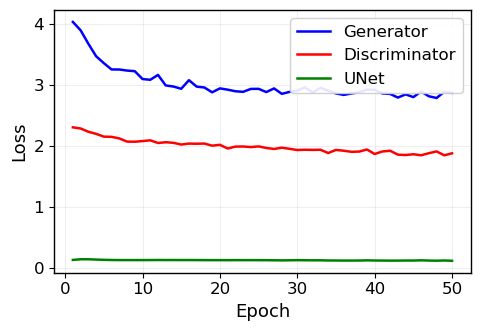

Found 5 testing imgs

Processing image 1/3: pic3_10_17.png


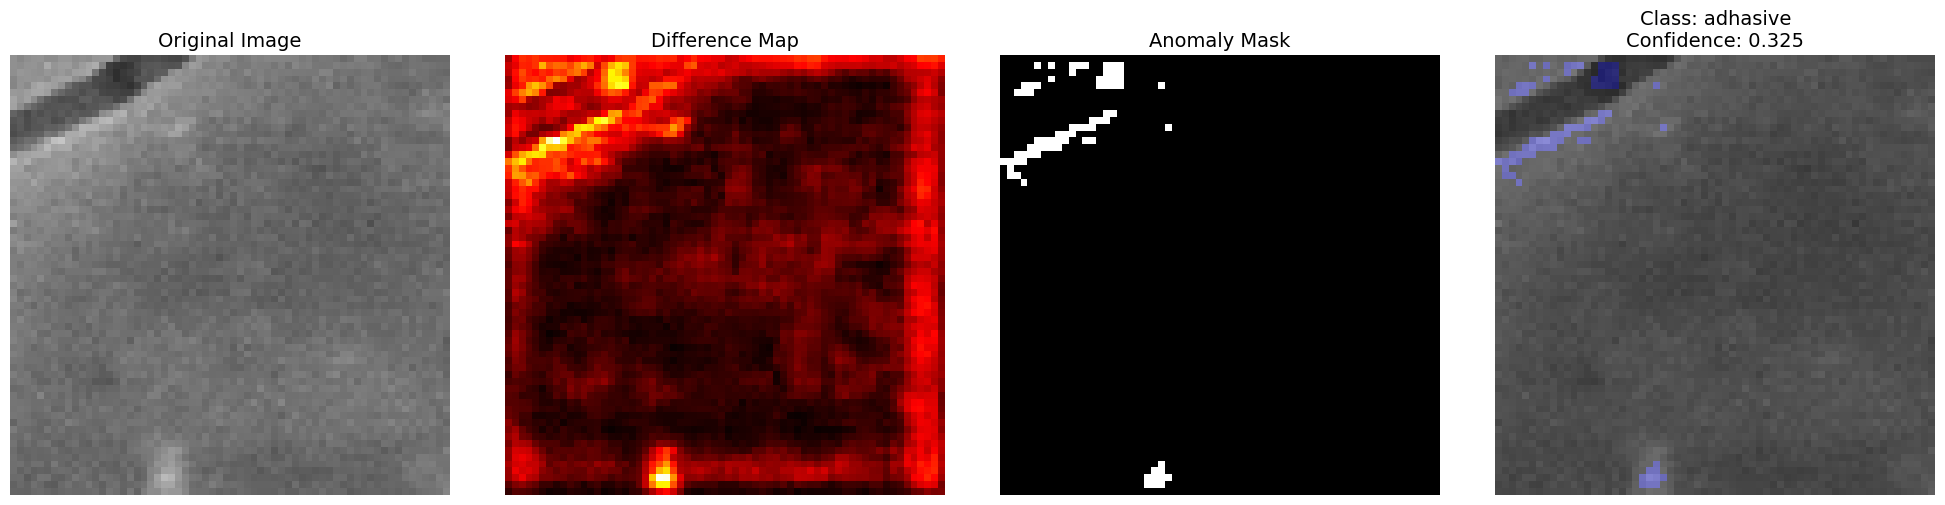

Class prediction:
  normal: 0.1953
  abrasive: 0.1363
  adhasive: 0.3248
  cracks: 0.1118
  delamination: 0.2318

Processing image 2/3: pic3_10_16.png


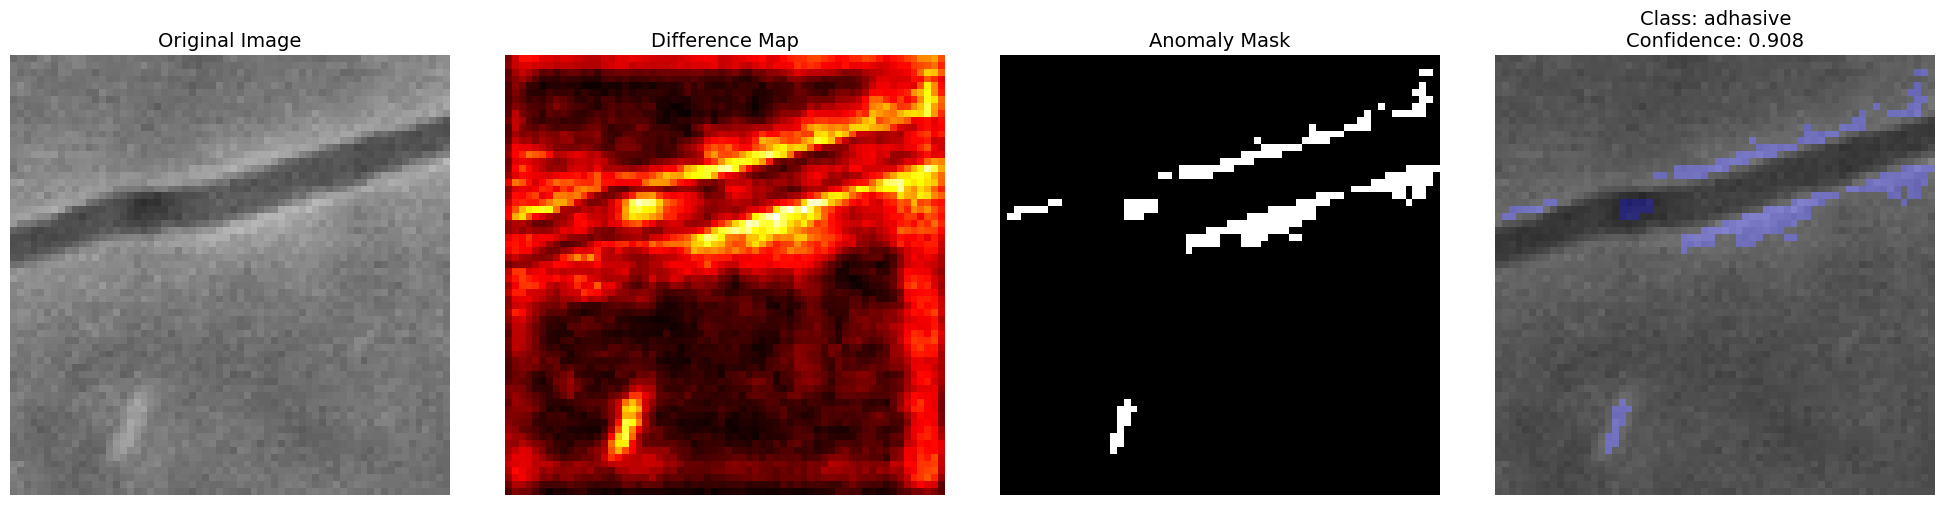

Class prediction:
  normal: 0.0415
  abrasive: 0.0042
  adhasive: 0.9078
  cracks: 0.0008
  delamination: 0.0457

Processing image 3/3: pic5_5_6.jpg


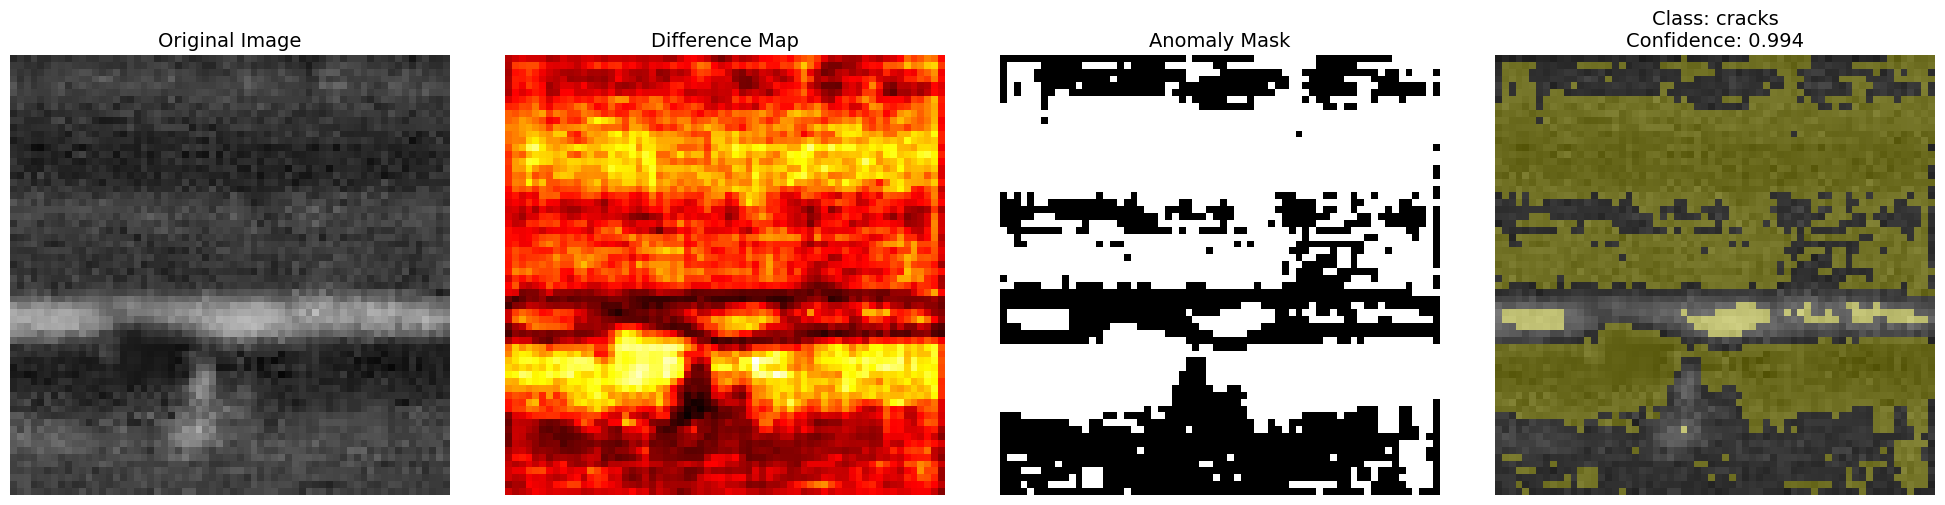

Class prediction:
  normal: 0.0000
  abrasive: 0.0000
  adhasive: 0.0000
  cracks: 0.9944
  delamination: 0.0056


In [12]:
def main():
    normal_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_normalimags"
    defect_folders = [
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\abrasive",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\adhesive", 
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\cracks",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\delamination"      
    ]
    test_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_abnormalimags"
    
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize([0.5] * 3, [0.5] * 3)
    ])
    
    dataset = ACGANDataset(normal_folder, defect_folders, transform)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=0)
    
    acgan = ACGANAnomalyDetection(num_classes=5, img_size=64)
    
    acgan.train(dataloader, epochs=50)

    torch.save({
        'generator': acgan.generator.state_dict(),
        'discriminator': acgan.discriminator.state_dict(),
        'unet': acgan.unet.state_dict(),
    }, r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\final_hybrid_model.pth")

    acgan.plot_for_paper(save_path='hybrid_losses.png')
   
    torch.save({
        'generator': acgan.generator.state_dict(),
        'discriminator': acgan.discriminator.state_dict(),
        'unet': acgan.unet.state_dict(),
    }, r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\final_hybrid_model.pth")
    
    def get_test_images(folder_path, num_samples=5):
        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
        all_images = []
        for ext in extensions:
            all_images.extend(glob.glob(os.path.join(folder_path, ext)))
        return random.sample(all_images, min(num_samples, len(all_images)))
    
    test_images = get_test_images(test_folder, num_samples=5)
    
    if test_images:
        print(f"Found {len(test_images)} testing imgs")
        acgan.visualize_results(test_images[:min(3, len(test_images))])

if __name__ == "__main__":
    main()

Loading discriminator for feature extraction...
Extracting features from your dataset...
Extracting features from images...
Processing normal...
Found 68 images in normal
Processing abrasive...
Found 63 images in abrasive


C:\Users\Administrator\AppData\Local\Temp\ipykernel_13028\600646248.py:46: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location='cp

Processing adhesive...
Found 46 images in adhesive
Processing cracks...
Found 54 images in cracks
Processing delamination...
Found 58 images in delamination
Extracted 150 samples with 2048 features each

=== COMPARING FEATURE SPACES ===
Creating comparison of feature space visualizations...


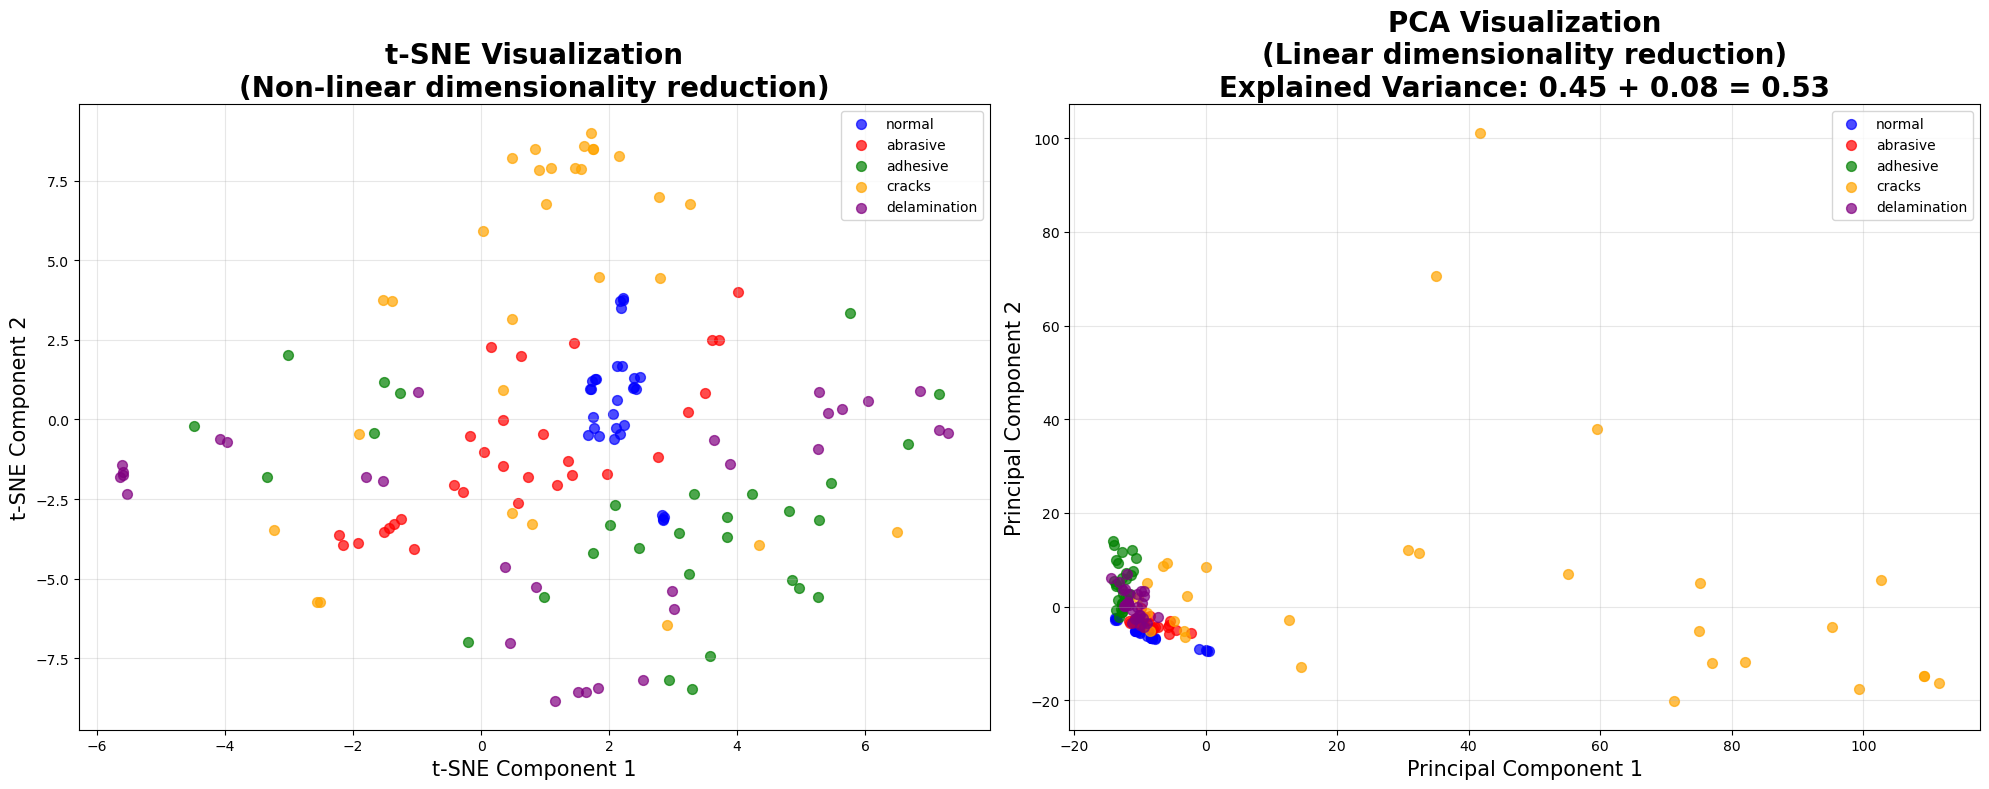


=== OUTLIER ANALYSIS ===
Found 2 potential outliers:
  pic4_9_125.png (cracks): distance 10.054
  pic5_13_11.png (abrasive): distance 6.109


In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from torchvision import transforms
from PIL import Image
import os
import glob

class Discriminator(nn.Module):
    def __init__(self, num_classes=5, img_channels=3):
        super(Discriminator, self).__init__()
        
        def discriminator_block(in_filters, out_filters, bn=True):
            block = [nn.Conv2d(in_filters, out_filters, 3, 2, 1),
                    nn.LeakyReLU(0.2, inplace=True),
                    nn.Dropout2d(0.3)]
            if bn:
                block.append(nn.BatchNorm2d(out_filters, 0.8))
            return block
        
        self.model = nn.Sequential(
            *discriminator_block(img_channels, 16, bn=False),
            *discriminator_block(16, 32),
            *discriminator_block(32, 64),
            *discriminator_block(64, 128),
        )
        
        ds_size = 64 // 2 ** 4
        self.adv_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, 1), nn.Sigmoid())
        self.aux_layer = nn.Sequential(nn.Linear(128 * ds_size ** 2, num_classes), nn.Softmax(dim=1))
    
    def forward(self, img):
        out = self.model(img)
        out = out.view(out.shape[0], -1)
        validity = self.adv_layer(out)
        label = self.aux_layer(out)
        return validity, label

def load_discriminator(model_path):
    discriminator = Discriminator(num_classes=5)
    checkpoint = torch.load(model_path, map_location='cpu')
    discriminator.load_state_dict(checkpoint['discriminator'])
    discriminator.eval()
    return discriminator

def extract_features_from_images(discriminator, folder_paths, class_names, num_images_per_class=20):
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize([0.5] * 3, [0.5] * 3)
    ])
    
    all_features = []
    all_labels = []
    all_filenames = []
    
    
    for class_idx, folder_path in enumerate(folder_paths):
        print(f"Processing {class_names[class_idx]}...")
        
        if not os.path.exists(folder_path):
            print(f"Warning: Folder {folder_path} does not exist!")
            continue
        
        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
        images = []
        for ext in extensions:
            images.extend(glob.glob(os.path.join(folder_path, ext)))
        
        print(f"Found {len(images)} images in {class_names[class_idx]}")
        
        images = images[:num_images_per_class]
        
        for img_path in images:
            try:
                img = Image.open(img_path).convert('RGB')
                img_tensor = transform(img).unsqueeze(0)
              
                with torch.no_grad():
                    conv_features = discriminator.model(img_tensor)
                    features = conv_features.view(conv_features.size(0), -1)
                
                all_features.append(features.squeeze().numpy())
                all_labels.append(class_idx)
                all_filenames.append(os.path.basename(img_path))
                
            except Exception as e:
                print(f"Error processing {img_path}: {e}")

    if len(all_features) == 0:
        print("No features were extracted.")
        return np.array([]), np.array([]), []
    
    return np.array(all_features), np.array(all_labels), all_filenames

def visualize_feature_space(features, labels, filenames, class_names, method='tsne'):
    
    if method == 'tsne':
        reducer = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
        embeddings = reducer.fit_transform(features)
        title = 't-SNE Visualization of Feature Space'
    else method == 'pca':
        reducer = PCA(n_components=2, random_state=42)
        embeddings = reducer.fit_transform(features)
        variance_ratio = reducer.explained_variance_ratio_
        title = f'PCA Visualization (Variance: {variance_ratio[0]:.2f}, {variance_ratio[1]:.2f})'

    plt.figure(figsize=(12, 10))
    
    colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        plt.scatter(embeddings[mask, 0], embeddings[mask, 1], 
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.5)
    
    plt.title(title, fontsize=16, fontweight='bold')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    unique, counts = np.unique(labels, return_counts=True)
    plt.figtext(0.02, 0.02, f"Total samples: {len(features)}\n" +
               "\n".join([f"{class_names[idx]}: {count}" for idx, count in zip(unique, counts)]),
               fontsize=20, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    return embeddings

def analyze_clusters(embeddings, labels, class_names):
    from sklearn.metrics import silhouette_score, calinski_harabasz_score
    
    if len(np.unique(labels)) > 1:
        silhouette = silhouette_score(embeddings, labels)
        calinski = calinski_harabasz_score(embeddings, labels)
        
        print(f"Silhouette Score: {silhouette:.3f}")
        print(f"Calinski-Harabasz Score: {calinski:.3f}")
        
    print("\n=== CLASS SEPARATION ===")
    from scipy.spatial.distance import cdist
    
    centroids = []
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        if np.sum(mask) > 0:
            centroid = np.mean(embeddings[mask], axis=0)
            centroids.append(centroid)
    
    if len(centroids) > 1:
        distances = cdist(centroids, centroids)
        np.fill_diagonal(distances, np.inf)  
        
        min_distances = np.min(distances, axis=1)
        avg_min_distance = np.mean(min_distances)
        
        print(f"Average minimum inter-class distance: {avg_min_distance:.3f}")
        
        min_idx = np.unravel_index(np.argmin(distances), distances.shape)
        max_idx = np.unravel_index(np.argmax(distances), distances.shape)
        
        print(f"Most similar classes: {class_names[min_idx[0]]} ↔ {class_names[min_idx[1]]}")
        print(f"Most different classes: {class_names[max_idx[0]]} ↔ {class_names[max_idx[1]]}")

def visualize_outliers(embeddings, labels, filenames, class_names):
    outliers = []
    
    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        if np.sum(mask) > 1: 
            class_embeddings = embeddings[mask]
            class_filenames = [filenames[i] for i in range(len(filenames)) if labels[i] == class_idx]
            
            centroid = np.mean(class_embeddings, axis=0)
            distances = np.linalg.norm(class_embeddings - centroid, axis=1)
            
            threshold = np.mean(distances) + 2 * np.std(distances)
            outlier_indices = np.where(distances > threshold)[0]
            
            for idx in outlier_indices:
                outliers.append({
                    'filename': class_filenames[idx],
                    'class': class_names[class_idx],
                    'distance': distances[idx],
                    'embedding': class_embeddings[idx]
                })
    
    if outliers:
        print(f"Found {len(outliers)} potential outliers:")
        for outlier in sorted(outliers, key=lambda x: x['distance'], reverse=True)[:5]:  # Top 5
            print(f"  {outlier['filename']} ({outlier['class']}): distance {outlier['distance']:.3f}")


def compare_feature_spaces(features, labels, class_names):
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
    embeddings_tsne = tsne.fit_transform(features)

    pca = PCA(n_components=2, random_state=42)
    embeddings_pca = pca.fit_transform(features)
    variance_ratio = pca.explained_variance_ratio_
    
    colors = ['blue', 'red', 'green', 'orange', 'purple']

    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        ax1.scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50)
    
    ax1.set_title('t-SNE Visualization\n(Non-linear dimensionality reduction)', fontsize=20, fontweight='bold')
    ax1.set_xlabel('t-SNE Component 1',fontsize=15)
    ax1.set_ylabel('t-SNE Component 2',fontsize=15)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    for class_idx in range(len(class_names)):
        mask = labels == class_idx
        ax2.scatter(embeddings_pca[mask, 0], embeddings_pca[mask, 1],
                   c=colors[class_idx % len(colors)], 
                   label=class_names[class_idx],
                   alpha=0.7, s=50)
    
    ax2.set_title(f'PCA Visualization\n(Linear dimensionality reduction)\nExplained Variance: {variance_ratio[0]:.2f} + {variance_ratio[1]:.2f} = {variance_ratio.sum():.2f}', 
                 fontsize=20, fontweight='bold')
    ax2.set_xlabel('Principal Component 1',fontsize=15)
    ax2.set_ylabel('Principal Component 2',fontsize=15)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return embeddings_tsne, embeddings_pca

if __name__ == "__main__":
    normal_folder = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_normalimags"
    defect_folders = [
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\abrasive",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\adhasive", 
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\cracks",
        r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\tzh_wear\delamination"      
    ]
    
    CLASS_NAMES = ['normal', 'abrasive', 'adhesive', 'cracks', 'delamination']
    MODEL_PATH = r"C:\Users\Administrator\OneDrive\Desktop\Gan+Unet project\hybrid codes\final_hybrid_model.pth"
    
    all_folders = [normal_folder] + defect_folders
    
    discriminator = load_discriminator(MODEL_PATH)

    features, labels, filenames = extract_features_from_images(
        discriminator, all_folders, CLASS_NAMES, num_images_per_class=30
    )
    
    print(f"Extracted {len(features)} samples with {features.shape[1]} features each")
    embeddings_tsne, embeddings_pca = compare_feature_spaces(features, labels, CLASS_NAMES)

    visualize_outliers(embeddings_tsne, labels, filenames, CLASS_NAMES)